In [1]:
!pip install -q torch torchvision torchaudio
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import os
import cv2
from google.colab import drive
import zipfile
import itertools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 114.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 91.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 53.7 MB/s eta 0:00:00


In [2]:
drive.mount('/content/drive')
zip_path = '/content/drive/MyDrive/ani.zip'
extract_path = '/content/retinal'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
print("Extracted to:", extract_path)

Mounted at /content/drive
Extracted to: /content/retinal


In [3]:
base_path = '/content/retinal/Dataset - train+val+test'
train_path = os.path.join(base_path, 'train')
val_path   = os.path.join(base_path, 'val')
test_path  = os.path.join(base_path, 'test')

In [4]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

In [5]:
from torchvision.datasets import ImageFolder
from torch.utils.data import Subset
import torchvision.transforms as transforms
import random

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])
train_dataset = ImageFolder(train_path, transform=train_transform)
val_dataset   = ImageFolder(val_path, transform=val_transform)
test_dataset  = ImageFolder(test_path, transform=val_transform)

class_map = train_dataset.class_to_idx
print("Class mapping:", class_map)
normal_class_idx = class_map['NORMAL']

def filter_some_random(dataset, exclude_class_idx, max_samples=500):
    indices = [i for i, (_, label) in enumerate(dataset.samples) if label != exclude_class_idx]
    sampled_indices = random.sample(indices, min(len(indices), max_samples))
    return Subset(dataset, sampled_indices)

train_dataset = filter_some_random(train_dataset, normal_class_idx, 1000)
val_dataset   = filter_some_random(val_dataset, normal_class_idx, 300)
test_dataset  = filter_some_random(test_dataset, normal_class_idx, 300)

class_names = ['CNV', 'DME', 'DRUSEN']


Class mapping: {'CNV': 0, 'DME': 1, 'DRUSEN': 2, 'NORMAL': 3}


In [6]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [7]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=1, gamma=2, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction
        self.ce = nn.CrossEntropyLoss(reduction='none')

    def forward(self, inputs, targets):
        ce_loss = self.ce(inputs, targets)
        pt = torch.exp(-ce_loss)
        focal_loss = self.alpha * (1 - pt) ** self.gamma * ce_loss
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

In [8]:
criterion = FocalLoss(alpha=1, gamma=2)

In [17]:
from torchvision import models
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet50(pretrained=True)

for param in model.parameters():
    param.requires_grad = False

for name, child in model.named_children():
    if name in ['layer3', 'layer4', 'fc']:
        for param in child.parameters():
            param.requires_grad = True

num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, len(class_names))
model = model.to(device)

criterion = FocalLoss(alpha=1, gamma=2)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.0005)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

subset_size = 25000
subset_dataset, _ = random_split(train_dataset, [subset_size, len(train_dataset) - subset_size])
subset_loader = DataLoader(subset_dataset, batch_size=32, shuffle=True)

val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

Epoch [1/15] Loss: 6.6025, Val Acc: 63.33%
Epoch [2/15] Loss: 4.2227, Val Acc: 85.00%
Epoch [3/15] Loss: 3.4304, Val Acc: 77.67%
Epoch [4/15] Loss: 1.9256, Val Acc: 90.00%
Epoch [5/15] Loss: 2.7334, Val Acc: 85.67%
Epoch [6/15] Loss: 2.3167, Val Acc: 83.33%
Epoch [7/15] Loss: 2.1791, Val Acc: 91.67%
Epoch [8/15] Loss: 1.6475, Val Acc: 93.67%
Epoch [9/15] Loss: 1.4330, Val Acc: 92.00%
Epoch [10/15] Loss: 1.3740, Val Acc: 91.33%
Epoch [11/15] Loss: 1.6993, Val Acc: 90.67%
Early stopping triggered


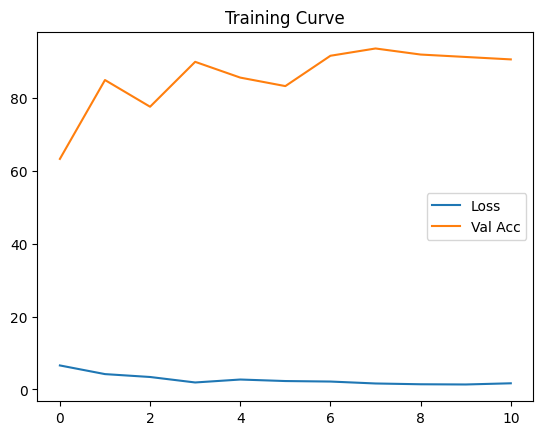

In [18]:
def train_model(model, train_loader, val_loader, epochs=5, patience=3):
    best_acc = 0
    patience_counter = 0
    train_losses, val_accuracies = [], []

    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        correct = total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_acc = 100 * correct / total
        train_losses.append(total_loss)
        val_accuracies.append(val_acc)

        print(f"Epoch [{epoch+1}/{epochs}] Loss: {total_loss:.4f}, Val Acc: {val_acc:.2f}%")

        scheduler.step(val_acc)


        if val_acc > best_acc:
            best_acc = val_acc
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("Early stopping triggered")
                break

    plt.plot(train_losses, label='Loss')
    plt.plot(val_accuracies, label='Val Acc')
    plt.legend()
    plt.title("Training Curve")
    plt.show()

train_model(model, subset_loader, val_loader, epochs=15)

Classification Report:
              precision    recall  f1-score   support

         CNV       0.98      0.92      0.95       207
         DME       0.98      0.91      0.95        57
      DRUSEN       0.68      1.00      0.81        36

    accuracy                           0.93       300
   macro avg       0.88      0.94      0.90       300
weighted avg       0.95      0.93      0.93       300



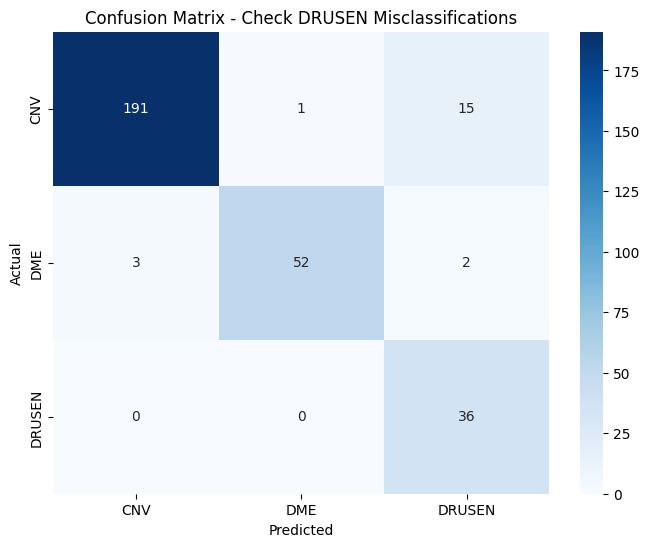

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def evaluate_model(model, test_loader, class_names):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    print("Classification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix - Check DRUSEN Misclassifications')
    plt.show()
evaluate_model(model, test_loader, class_names)

In [13]:
def generate_gradcam(model, image_tensor, class_idx, target_layer):
    model.eval()
    gradients, activations = [], []

    def backward_hook(module, grad_in, grad_out): gradients.append(grad_out[0])
    def forward_hook(module, input, output): activations.append(output)

    handle_fw = target_layer.register_forward_hook(forward_hook)
    handle_bw = target_layer.register_backward_hook(backward_hook)

    output = model(image_tensor)
    model.zero_grad()
    class_loss = output[0, class_idx]
    class_loss.backward()

    grads_val = gradients[0].cpu().data.numpy()
    acts_val = activations[0].cpu().data.numpy()
    weights = np.mean(grads_val, axis=(2, 3))[0, :]
    cam = np.zeros(acts_val.shape[2:], dtype=np.float32)
    for i, w in enumerate(weights): cam += w * acts_val[0, i, :, :]
    cam = np.maximum(cam, 0)
    cam = cv2.resize(cam, (224, 224))
    cam -= np.min(cam)
    cam /= np.max(cam)

    handle_fw.remove()
    handle_bw.remove()
    return cam

In [14]:
os.makedirs("/content/gradcam_outputs", exist_ok=True)

def save_gradcam_batch(model, dataset, count=25):
    model.eval()
    for i in range(count):
        image, label = dataset[i]
        input_tensor = image.unsqueeze(0).to(device)
        output = model(input_tensor)
        pred_class = torch.argmax(output).item()
        heatmap = generate_gradcam(model, input_tensor, pred_class, model.layer4[1].conv2)
        image_np = image.permute(1, 2, 0).cpu().numpy()
        image_np = (image_np * 0.5) + 0.5
        heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
        heatmap_color = np.float32(heatmap_color) / 255
        overlay = heatmap_color[..., ::-1] * 0.4 + image_np
        plt.imsave(f"/content/gradcam_outputs/img_{i}_true_{class_names[label]}_pred_{class_names[pred_class]}.png", np.clip(overlay, 0, 1))
    print(f"Saved {count} Grad-CAM overlays")

save_gradcam_batch(model, test_dataset, count=25)

/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:1830: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


Saved 25 Grad-CAM overlays


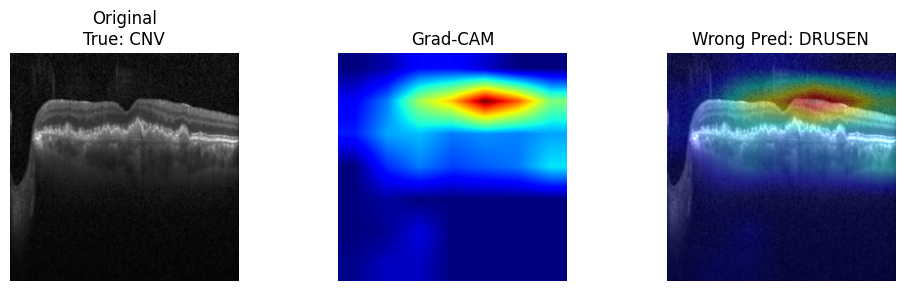

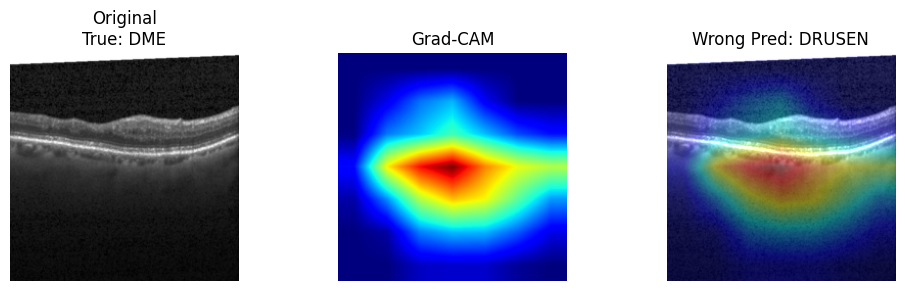

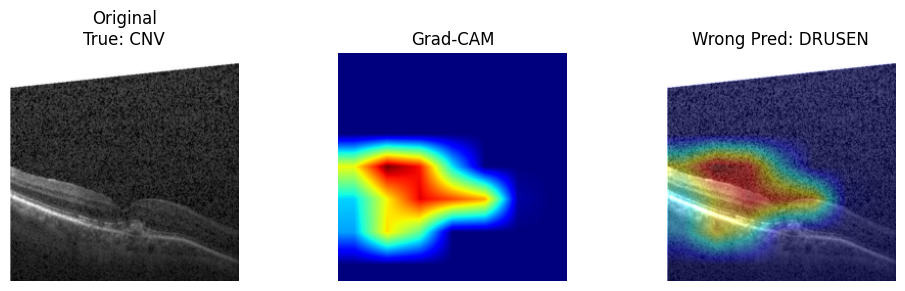

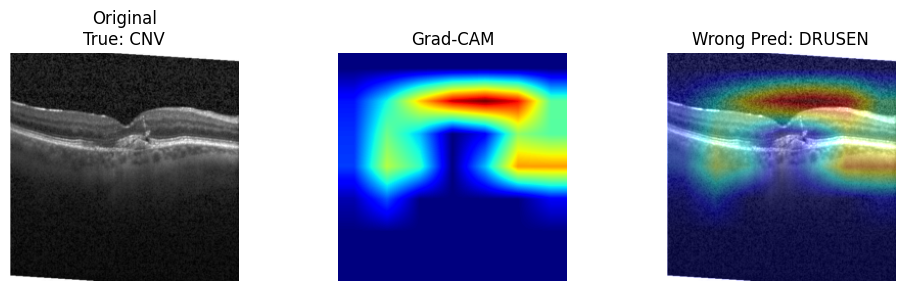

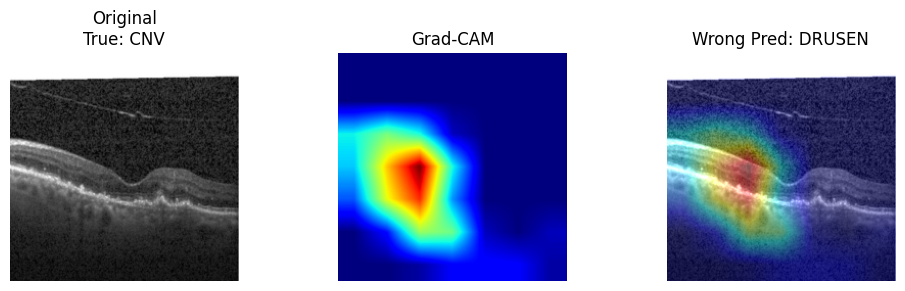

In [15]:
def visualize_false_positives(model, dataset, max_images=5):
    model.eval()
    shown = 0
    for i in range(len(dataset)):
        image, label = dataset[i]
        input_tensor = image.unsqueeze(0).to(device)
        output = model(input_tensor)
        pred_class = torch.argmax(output).item()
        if pred_class != label:
            heatmap = generate_gradcam(model, input_tensor, pred_class, model.layer4[1].conv2)
            image_np = image.permute(1, 2, 0).cpu().numpy()
            image_np = (image_np * 0.5) + 0.5
            heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap), cv2.COLORMAP_JET)
            heatmap_color = np.float32(heatmap_color) / 255
            overlay = heatmap_color[..., ::-1] * 0.4 + image_np
            plt.figure(figsize=(10, 3))
            plt.subplot(1, 3, 1)
            plt.imshow(image_np)
            plt.title(f"Original\nTrue: {class_names[label]}")
            plt.axis('off')
            plt.subplot(1, 3, 2)
            plt.imshow(heatmap, cmap='jet')
            plt.title("Grad-CAM")
            plt.axis('off')
            plt.subplot(1, 3, 3)
            plt.imshow(np.clip(overlay, 0, 1))
            plt.title(f"Wrong Pred: {class_names[pred_class]}")
            plt.axis('off')
            plt.tight_layout()
            plt.show()
            shown += 1
            if shown >= max_images:
                break

visualize_false_positives(model, test_dataset)